# DAC-301 Deep Learning Assignment
## Glasses Detection with a Residual CNN (Self-Contained Notebook)

**Student:** Chakilam Lalith Sai  **Roll number:** 24125009

**Code repository:** https://github.com/D3LET3-57/GlassesNet

This single notebook contains the complete project: data pipeline, a
residual CNN, the training loop, the hyperparameter search, the 5-fold
cross-validation results, the TTA/ensemble inference code, the final
submission preview, and the reproducibility discussion. It does not import
any project-local module; all model and training code is defined below.

**Task.** Binary classification of 512x512 RGB face images: wearing glasses
(1) or not (0). Training set: 24,499 images (12,288 glasses / 12,211
no-glasses). Test set: 5,412 images.

**Final result.** 5-fold mean validation accuracy **99.9510% +/- 0.0277%**,
mean validation F1 **99.9511%**; test score **0.99872** (about 7 errors in
5,412 images).

**Design summary.** The network is a residual CNN implemented with
`torch.nn`. All model, training, metric and inference computations use
PyTorch; pandas/PIL handle data I/O and matplotlib produces the figures.


## 1. Setup

The notebook uses standard-library, PyTorch, torchvision, pandas, PIL and
matplotlib imports.


In [1]:
import copy
import json
import math
import os
import random
import time
from dataclasses import dataclass, field, asdict
from typing import List

import pandas as pd
import torch
import torch.nn as nn
import torchvision.transforms as T
from PIL import Image
from torch.utils.data import Dataset, DataLoader
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())


PyTorch: 2.11.0+cu128
CUDA available: False


In [2]:
# Dataset location. If you run this notebook outside the repository, set
# GLASSES_DATA_ROOT (or edit DATA_ROOT) to the folder that contains
# kaggle/ and Dataset/.
DATA_ROOT = os.environ.get("GLASSES_DATA_ROOT", "../data")
TRAIN_CSV = os.path.join(DATA_ROOT, "kaggle/kaggle/train.csv")
TRAIN_DIR = os.path.join(DATA_ROOT, "kaggle/kaggle")
TEST_CSV = os.path.join(DATA_ROOT, "Dataset/test_dataset.csv")
TEST_DIR = os.path.join(DATA_ROOT, "Dataset/testimages")
DATA_AVAILABLE = os.path.exists(TRAIN_CSV)
print("Data root:", os.path.abspath(DATA_ROOT))
print("Dataset available:", DATA_AVAILABLE)


Data root: /home2/home/chakilam_sai/acadss/dl/glasses-scratch/data
Dataset available: True


## 2. Data pipeline

Images are loaded with PIL, converted to RGB, resized/cropped and normalized
with mean/std 0.5. Training augmentation is RandomResizedCrop (scale 0.65-1.0,
ratio 0.8-1.25), horizontal flip, +/-7 degree rotation, color jitter and random
erasing. Validation uses resize-short-side 256 + center crop.

Folds are deterministic and stratified with a fixed split seed (42). Each fold
trains on 19,598 images and validates on 4,901 (the last fold has 19,604/4,895
due to integer chunking).


In [3]:
MEAN = (0.5, 0.5, 0.5)
STD = (0.5, 0.5, 0.5)


class GlassesDataset(Dataset):
    """Image dataset backed by a pandas DataFrame."""

    def __init__(self, df, root_dir, transform, is_test=False):
        self.df = df.reset_index(drop=True)
        self.root_dir = root_dir
        self.transform = transform
        self.is_test = is_test
        self.files = self.df["file"].tolist()
        self.ids = self.df["id"].astype(str).tolist()
        self.labels = (None if is_test
                       else self.df["glasses"].astype(int).tolist())

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        path = os.path.join(self.root_dir, self.files[idx])
        image = Image.open(path).convert("RGB")
        image = self.transform(image)
        if self.is_test:
            return image, self.ids[idx]
        return image, self.labels[idx]


def build_train_transform(cfg):
    ops = []
    if cfg.aug_random_resized_crop:
        ops.append(T.RandomResizedCrop(
            cfg.image_size, scale=(cfg.aug_scale_min, 1.0),
            ratio=(0.8, 1.25)))
    else:
        ops.append(T.Resize((cfg.image_size, cfg.image_size)))
    if cfg.aug_hflip:
        ops.append(T.RandomHorizontalFlip(p=0.5))
    if cfg.aug_rotation > 0:
        ops.append(T.RandomRotation(cfg.aug_rotation))
    if cfg.aug_color_jitter > 0:
        j = cfg.aug_color_jitter
        ops.append(T.ColorJitter(brightness=j, contrast=j, saturation=j,
                                 hue=min(j / 4, 0.05)))
    ops += [T.ToTensor(), T.Normalize(MEAN, STD)]
    if cfg.aug_random_erasing > 0:
        ops.append(T.RandomErasing(p=cfg.aug_random_erasing,
                                   scale=(0.02, 0.12), ratio=(0.5, 2.0)))
    return T.Compose(ops)


def build_eval_transform(image_size):
    return T.Compose([
        T.Resize(image_size + 32),
        T.CenterCrop(image_size),
        T.ToTensor(),
        T.Normalize(MEAN, STD),
    ])


def stratified_folds(labels, num_folds, seed):
    """Deterministic stratified (train_idx, val_idx) fold definitions."""
    g = torch.Generator().manual_seed(seed)
    fold_val = [[] for _ in range(num_folds)]
    for cls in labels.unique():
        idx = torch.nonzero(labels == cls, as_tuple=False).flatten()
        idx = idx[torch.randperm(len(idx), generator=g)]
        for k, chunk in enumerate(torch.chunk(idx, num_folds)):
            fold_val[k].append(chunk)
    all_idx = torch.arange(len(labels))
    folds = []
    for k in range(num_folds):
        val_idx = torch.cat(fold_val[k]).sort().values
        mask = torch.ones(len(labels), dtype=torch.bool)
        mask[val_idx] = False
        folds.append((all_idx[mask], val_idx))
    return folds


def build_loaders(cfg, train_csv, train_dir, fold=None):
    df = pd.read_csv(train_csv)
    if cfg.limit_per_class > 0:
        parts = [
            g.sample(n=min(cfg.limit_per_class, len(g)),
                     random_state=cfg.seed)
            for _, g in df.groupby("glasses")
        ]
        df = pd.concat(parts).sample(frac=1.0,
                                     random_state=cfg.seed).reset_index(drop=True)
    labels = torch.tensor(df["glasses"].tolist(), dtype=torch.long)
    folds = stratified_folds(labels, cfg.num_folds, cfg.split_seed)
    f = cfg.val_fold if fold is None else fold
    train_idx, val_idx = folds[f]
    train_df = df.iloc[train_idx.tolist()].reset_index(drop=True)
    val_df = df.iloc[val_idx.tolist()].reset_index(drop=True)
    train_ds = GlassesDataset(train_df, train_dir, build_train_transform(cfg))
    val_ds = GlassesDataset(val_df, train_dir, build_eval_transform(cfg.image_size))
    common = dict(batch_size=cfg.batch_size, num_workers=cfg.num_workers,
                  pin_memory=torch.cuda.is_available(),
                  persistent_workers=cfg.num_workers > 0)
    if cfg.num_workers > 0:
        common["prefetch_factor"] = 4
    train_loader = DataLoader(train_ds, shuffle=True, drop_last=True, **common)
    val_loader = DataLoader(val_ds, shuffle=False, **common)
    return train_loader, val_loader, train_df, val_df


Train images: 24499
glasses
glasses       12288
no glasses    12211
Name: count, dtype: int64
Test images: 5412
Fold sizes (train, val): [(19598, 4901), (19598, 4901), (19598, 4901), (19598, 4901), (19604, 4895)]


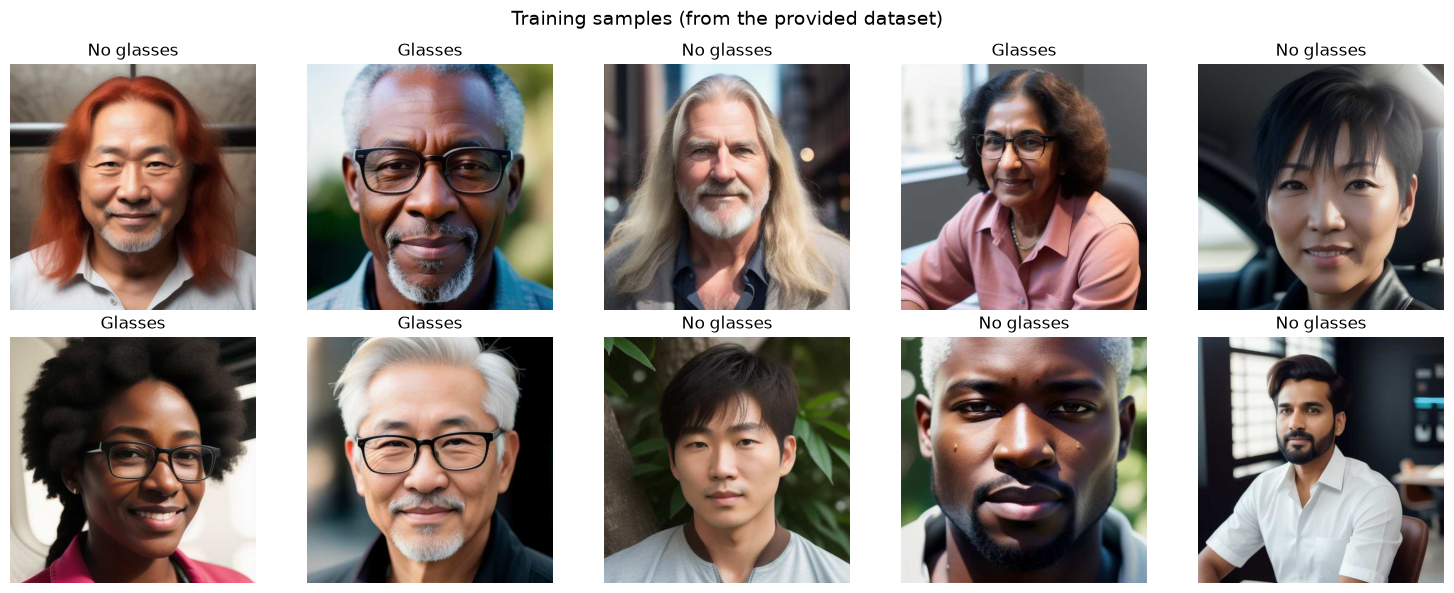

In [4]:
if DATA_AVAILABLE:
    train_df_full = pd.read_csv(TRAIN_CSV)
    test_df_full = pd.read_csv(TEST_CSV)
    print(f"Train images: {len(train_df_full)}")
    print(train_df_full["glasses"].value_counts().rename(
        {0: "no glasses", 1: "glasses"}))
    print(f"Test images: {len(test_df_full)}")

    labels = torch.tensor(train_df_full["glasses"].tolist(), dtype=torch.long)
    folds = stratified_folds(labels, num_folds=5, seed=42)
    print("Fold sizes (train, val):",
          [(len(tr), len(va)) for tr, va in folds])

    fig, axes = plt.subplots(2, 5, figsize=(15, 6))
    fig.suptitle("Training samples (from the provided dataset)", fontsize=14)
    for ax, (_, row) in zip(axes.flat,
                            train_df_full.sample(10,
                                                 random_state=7).iterrows()):
        img = Image.open(os.path.join(TRAIN_DIR, row["file"])).convert("RGB")
        ax.imshow(img)
        ax.set_title("Glasses" if row["glasses"] == 1 else "No glasses")
        ax.axis("off")
    plt.tight_layout()
    plt.show()
else:
    print("Dataset not found. Set GLASSES_DATA_ROOT to the folder containing "
          "kaggle/ and Dataset/ to run the data cells and the live demo.")


## 3. Configurable hyperparameters and architecture

Every assignment-required hyperparameter is a field of `Config`: learning
rate, momentum, number of hidden stages (`num_hidden`), stage widths (`sizes`),
activation, loss, optimizer, batch size, annealing, plus depth per stage,
dropout, weight decay and augmentation settings.

The network is a residual CNN built with `torch.nn`: a 7x7 stem (3->64,
stride 2) with max-pooling, four stages of BasicBlocks with widths
[64, 128, 256, 512] and two blocks per stage, global average pooling, dropout
0.2 and a linear layer to 2 logits. It has **11,177,538** parameters and is
trained from random initialization.


In [5]:
@dataclass
class Config:
    # data / split
    image_size: int = 224
    num_folds: int = 5
    val_fold: int = 0
    seed: int = 42
    split_seed: int = 42
    num_workers: int = 0
    limit_per_class: int = 0

    # architecture
    num_hidden: int = 4
    sizes: List[int] = field(default_factory=lambda: [64, 128, 256, 512])
    blocks_per_stage: List[int] = field(default_factory=lambda: [2, 2, 2, 2])
    activation: str = "relu"
    stem_width: int = 64
    dropout: float = 0.2

    # loss / optimizer
    loss: str = "cross_entropy"
    label_smoothing: float = 0.1
    opt: str = "adamw"
    lr: float = 1e-3
    momentum: float = 0.9
    weight_decay: float = 5e-4
    grad_clip: float = 1.0

    # schedule
    num_epochs: int = 90
    warmup_epochs: int = 5
    anneal: bool = True
    min_lr_ratio: float = 0.01

    # training
    batch_size: int = 128
    amp: bool = True
    ema: bool = True
    ema_decay: float = 0.999
    eval_ema: bool = True
    log_interval: int = 1

    # augmentation
    aug_random_resized_crop: bool = True
    aug_scale_min: float = 0.65
    aug_hflip: bool = True
    aug_rotation: float = 7.0
    aug_color_jitter: float = 0.2
    aug_random_erasing: float = 0.25

    # artifacts / inference
    run_name: str = "run"
    device: str = "cuda"
    output_dir: str = "demo_runs"
    init_from: str = ""
    tta_views: int = 4
    predict_batch_size: int = 192

    @property
    def output_size(self):
        return 2

    def to_dict(self):
        return asdict(self)


In [6]:
def get_activation(name, inplace=False):
    if name == "relu":
        return nn.ReLU(inplace=inplace)
    if name == "leaky_relu":
        return nn.LeakyReLU(0.1, inplace=inplace)
    if name == "silu":
        return nn.SiLU(inplace=inplace)
    if name == "gelu":
        return nn.GELU()
    if name == "sigmoid":
        return nn.Sigmoid()
    if name == "tanh":
        return nn.Tanh()
    raise ValueError(f"Unknown activation: {name}")


class BasicBlock(nn.Module):
    """Two 3x3 convolutions with a residual connection."""
    expansion = 1

    def __init__(self, in_ch, out_ch, stride=1, activation="relu"):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, 3, stride=stride,
                               padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_ch)
        self.act1 = get_activation(activation, inplace=True)
        self.conv2 = nn.Conv2d(out_ch, out_ch, 3, stride=1,
                               padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_ch)
        self.act2 = get_activation(activation, inplace=True)
        if stride != 1 or in_ch != out_ch:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        else:
            self.shortcut = nn.Identity()

    def forward(self, x):
        identity = self.shortcut(x)
        out = self.act1(self.bn1(self.conv1(x)))
        out = self.bn2(self.conv2(out))
        return self.act2(out + identity)


class GlassesCNN(nn.Module):
    """Configurable ResNet-style binary classifier (from scratch)."""

    def __init__(self, cfg):
        super().__init__()
        self.cfg = cfg
        act = cfg.activation
        self.stem = nn.Sequential(
            nn.Conv2d(3, cfg.stem_width, 7, stride=2, padding=3, bias=False),
            nn.BatchNorm2d(cfg.stem_width),
            get_activation(act, inplace=True),
            nn.MaxPool2d(3, stride=2, padding=1),
        )
        stages = []
        in_ch = cfg.stem_width
        for s in range(cfg.num_hidden):
            out_ch = cfg.sizes[s]
            blocks = []
            for b in range(cfg.blocks_per_stage[s]):
                stride = 2 if (s > 0 and b == 0) else 1
                blocks.append(BasicBlock(in_ch, out_ch, stride, act))
                in_ch = out_ch
            stages.append(nn.Sequential(*blocks))
        self.stages = nn.Sequential(*stages)
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(cfg.dropout),
            nn.Linear(in_ch, cfg.output_size),
        )
        self._initialize_weights()

    def _initialize_weights(self):
        for m in self.modules():
            if isinstance(m, nn.Conv2d):
                if self.cfg.activation in ("relu", "leaky_relu", "silu"):
                    nn.init.kaiming_normal_(m.weight, mode="fan_out",
                                            nonlinearity="relu")
                else:
                    nn.init.xavier_normal_(m.weight)
            elif isinstance(m, nn.BatchNorm2d):
                nn.init.ones_(m.weight)
                nn.init.zeros_(m.bias)
            elif isinstance(m, nn.Linear):
                nn.init.normal_(m.weight, 0, 0.01)
                nn.init.zeros_(m.bias)

    def forward(self, x):
        x = self.stem(x)
        x = self.stages(x)
        return self.head(x)

    def num_parameters(self):
        return sum(p.numel() for p in self.parameters())


def build_model(cfg):
    return GlassesCNN(cfg)


In [7]:
model_preview = build_model(Config())
print(f"Trainable parameters: {model_preview.num_parameters():,}")
print(model_preview)


Trainable parameters: 11,177,538
GlassesCNN(
  (stem): Sequential(
    (0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  )
  (stages): Sequential(
    (0): Sequential(
      (0): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act1): ReLU(inplace=True)
        (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
        (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (act2): ReLU(inplace=True)
        (shortcut): Identity()
      )
      (1): BasicBlock(
        (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1,

## 4. Training loop and live hyperparameter tuning

The training loop uses cross-entropy with label smoothing, AdamW, warmup +
cosine decay, AMP, gradient clipping and an exponential moving average (EMA)
of the weights. Validation loss, accuracy and F1 are logged every epoch.

The next cells train a **small live demo** on CPU so the hyperparameters can
be changed and re-run immediately. The demo uses 64px, 500 images per class
and 4 epochs (~2-3 minutes). The final models used the full dataset at 224px
for 90 epochs; the same `fit` function is used.


In [8]:
def set_seed(seed):
    random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = True


def build_criterion(cfg):
    if cfg.loss == "cross_entropy":
        return nn.CrossEntropyLoss(label_smoothing=cfg.label_smoothing)
    return nn.MSELoss()


def build_optimizer(cfg, model):
    if cfg.opt == "adamw":
        return torch.optim.AdamW(model.parameters(), lr=cfg.lr,
                                 weight_decay=cfg.weight_decay)
    if cfg.opt == "adam":
        return torch.optim.Adam(model.parameters(), lr=cfg.lr,
                                weight_decay=cfg.weight_decay)
    if cfg.opt == "gd":
        return torch.optim.SGD(model.parameters(), lr=cfg.lr,
                               weight_decay=cfg.weight_decay)
    if cfg.opt in ("momentum", "nag"):
        return torch.optim.SGD(model.parameters(), lr=cfg.lr,
                               momentum=cfg.momentum,
                               nesterov=(cfg.opt == "nag"),
                               weight_decay=cfg.weight_decay)
    if cfg.opt == "sgd":
        return torch.optim.SGD(model.parameters(), lr=cfg.lr,
                               momentum=cfg.momentum,
                               weight_decay=cfg.weight_decay)
    raise ValueError(f"Unknown optimizer: {cfg.opt}")


def build_scheduler(cfg, optimizer):
    if not cfg.anneal:
        return None
    warmup = max(0, cfg.warmup_epochs)
    total = max(1, cfg.num_epochs)

    def lr_lambda(epoch):
        if epoch < warmup:
            return (epoch + 1) / max(1, warmup)
        progress = (epoch - warmup) / max(1, total - warmup)
        return cfg.min_lr_ratio + (1 - cfg.min_lr_ratio) * 0.5 * (
            1 + math.cos(math.pi * progress))

    return torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)


class ModelEMA:
    """Exponential moving average of weights and buffers."""

    def __init__(self, model, decay):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.step = 0

    @torch.no_grad()
    def update(self, model):
        self.step += 1
        d = min(self.decay, (1 + self.step) / (10 + self.step))
        for e, p in zip(self.ema.parameters(), model.parameters()):
            e.mul_(d).add_(p.detach(), alpha=1 - d)
        for e, b in zip(self.ema.buffers(), model.buffers()):
            e.copy_(b)


def _metrics(logits, labels):
    preds = logits.argmax(dim=1)
    correct = (preds == labels).sum().item()
    total = labels.numel()
    tp = ((preds == 1) & (labels == 1)).sum().item()
    fp = ((preds == 1) & (labels == 0)).sum().item()
    fn = ((preds == 0) & (labels == 1)).sum().item()
    precision = tp / (tp + fp) if (tp + fp) else 0.0
    recall = tp / (tp + fn) if (tp + fn) else 0.0
    f1 = 2 * precision * recall / (precision + recall) if (
        precision + recall) else 0.0
    return correct / total, f1


def _to_targets(labels, loss_type):
    if loss_type == "mse":
        t = torch.zeros(labels.size(0), 2, device=labels.device)
        t.scatter_(1, labels.unsqueeze(1), 1.0)
        return t
    return labels


def train_epoch(model, loader, criterion, optimizer, scaler, device, cfg):
    model.train()
    use_amp = cfg.amp and device.type == "cuda"
    running_loss = 0.0
    logits_all, labels_all = [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        targets = _to_targets(labels, cfg.loss)
        optimizer.zero_grad(set_to_none=True)
        with torch.amp.autocast("cuda", enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, targets)
        scaler.scale(loss).backward()
        if cfg.grad_clip > 0:
            scaler.unscale_(optimizer)
            nn.utils.clip_grad_norm_(model.parameters(), cfg.grad_clip)
        scaler.step(optimizer)
        scaler.update()
        running_loss += loss.item() * images.size(0)
        logits_all.append(logits.detach())
        labels_all.append(labels)
    logits_all = torch.cat(logits_all)
    labels_all = torch.cat(labels_all)
    acc, f1 = _metrics(logits_all, labels_all)
    return running_loss / len(loader.dataset), acc, f1


@torch.no_grad()
def evaluate(model, loader, criterion, device, cfg):
    model.eval()
    use_amp = cfg.amp and device.type == "cuda"
    running_loss = 0.0
    logits_all, labels_all = [], []
    for images, labels in loader:
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        targets = _to_targets(labels, cfg.loss)
        with torch.amp.autocast("cuda", enabled=use_amp):
            logits = model(images)
            loss = criterion(logits, targets)
        running_loss += loss.item() * images.size(0)
        logits_all.append(logits.float())
        labels_all.append(labels)
    logits_all = torch.cat(logits_all)
    labels_all = torch.cat(labels_all)
    acc, f1 = _metrics(logits_all, labels_all)
    return running_loss / len(loader.dataset), acc, f1


def _state_to_cpu(model):
    return {k: v.detach().cpu().clone()
            for k, v in model.state_dict().items()}


def fit(cfg, train_csv, train_dir, resume=False):
    """Train one model and return (best model, history)."""
    set_seed(cfg.seed)
    device = torch.device(cfg.device if torch.cuda.is_available() else "cpu")
    run_dir = os.path.join(cfg.output_dir, cfg.run_name)
    os.makedirs(run_dir, exist_ok=True)
    tag = f"fold{cfg.val_fold}"

    train_loader, val_loader, train_df, val_df = build_loaders(
        cfg, train_csv, train_dir)
    cfg_snapshot = cfg.to_dict()
    cfg_snapshot["train_size"] = len(train_df)
    cfg_snapshot["val_size"] = len(val_df)

    model = build_model(cfg).to(device)
    if cfg.init_from:
        ckpt = torch.load(cfg.init_from, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        print(f"Initialized weights from {cfg.init_from}")
    criterion = build_criterion(cfg)
    optimizer = build_optimizer(cfg, model)
    scheduler = build_scheduler(cfg, optimizer)
    use_amp = cfg.amp and device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp)
    ema = ModelEMA(model, cfg.ema_decay) if cfg.ema else None

    history = {
        "train_loss": [], "train_acc": [], "train_f1": [],
        "val_loss": [], "val_acc": [], "val_f1": [],
        "ema_val_loss": [], "ema_val_acc": [], "ema_val_f1": [],
        "lr": [], "epoch_time": [],
    }
    start_epoch = 0
    best_val_acc = 0.0
    best_val_f1 = 0.0
    best_epoch = -1
    best_used_ema = False

    last_path = os.path.join(run_dir, f"{tag}_last.pt")
    best_path = os.path.join(run_dir, f"{tag}_best.pt")
    metrics_path = os.path.join(run_dir, f"{tag}_metrics.jsonl")

    if resume and os.path.exists(last_path):
        ckpt = torch.load(last_path, map_location=device)
        model.load_state_dict(ckpt["model_state_dict"])
        optimizer.load_state_dict(ckpt["optimizer_state_dict"])
        if scheduler is not None and ckpt.get("scheduler_state_dict"):
            scheduler.load_state_dict(ckpt["scheduler_state_dict"])
        scaler.load_state_dict(ckpt["scaler_state_dict"])
        if ema is not None and ckpt.get("ema_state_dict"):
            ema.ema.load_state_dict(ckpt["ema_state_dict"])
        start_epoch = ckpt["epoch"]
        best_val_acc = ckpt.get("best_val_acc", 0.0)
        best_val_f1 = ckpt.get("best_val_f1", 0.0)
        best_epoch = ckpt.get("best_epoch", -1)
        best_used_ema = ckpt.get("best_used_ema", False)
        hist_path = os.path.join(run_dir, f"{tag}_history.json")
        if os.path.exists(hist_path):
            history = json.load(open(hist_path))
        print(f"Resumed {run_dir} at epoch {start_epoch}")

    print(f"Device: {device} | params: {model.num_parameters():,} | "
          f"train {len(train_df)} | val {len(val_df)} | {cfg.run_name}")
    print(f"Config: image_size={cfg.image_size} opt={cfg.opt} lr={cfg.lr} "
          f"loss={cfg.loss} ls={cfg.label_smoothing} bs={cfg.batch_size} "
          f"epochs={cfg.num_epochs} ema={cfg.ema}")

    for epoch in range(start_epoch, cfg.num_epochs):
        t0 = time.time()
        tr_loss, tr_acc, tr_f1 = train_epoch(
            model, train_loader, criterion, optimizer, scaler, device, cfg)
        val_loss, val_acc, val_f1 = evaluate(
            model, val_loader, criterion, device, cfg)

        ema_loss = ema_acc = ema_f1 = float("nan")
        if ema is not None:
            ema.update(model)
            ema_loss, ema_acc, ema_f1 = evaluate(
                ema.ema, val_loader, criterion, device, cfg)

        if scheduler is not None:
            scheduler.step()

        dt = time.time() - t0
        lr = optimizer.param_groups[0]["lr"]
        history["train_loss"].append(tr_loss)
        history["train_acc"].append(tr_acc)
        history["train_f1"].append(tr_f1)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        history["val_f1"].append(val_f1)
        history["ema_val_loss"].append(ema_loss)
        history["ema_val_acc"].append(ema_acc)
        history["ema_val_f1"].append(ema_f1)
        history["lr"].append(lr)
        history["epoch_time"].append(dt)

        score = ema_acc if (ema is not None and cfg.eval_ema) else val_acc
        if score > best_val_acc:
            best_val_acc = score
            best_val_f1 = ema_f1 if (ema is not None and cfg.eval_ema) else val_f1
            best_epoch = epoch + 1
            best_used_ema = ema is not None and cfg.eval_ema
            best_model = ema.ema if best_used_ema else model
            torch.save({
                "model_state_dict": _state_to_cpu(best_model),
                "config": cfg_snapshot,
                "epoch": epoch + 1,
                "val_acc": score,
                "val_f1": best_val_f1,
                "used_ema": best_used_ema,
            }, best_path)

        if (epoch + 1) % cfg.log_interval == 0:
            print(f"Epoch {epoch + 1:3d}/{cfg.num_epochs} | "
                  f"train loss {tr_loss:.4f} acc {tr_acc:.4f} f1 {tr_f1:.4f} | "
                  f"val loss {val_loss:.4f} acc {val_acc:.4f} f1 {val_f1:.4f} | "
                  f"ema acc {ema_acc:.4f} | lr {lr:.2e} | {dt:.1f}s",
                  flush=True)

        with open(metrics_path, "a") as f:
            f.write(json.dumps({
                "epoch": epoch + 1,
                "train_loss": tr_loss, "train_acc": tr_acc, "train_f1": tr_f1,
                "val_loss": val_loss, "val_acc": val_acc, "val_f1": val_f1,
                "ema_val_loss": ema_loss, "ema_val_acc": ema_acc,
                "ema_val_f1": ema_f1, "lr": lr, "epoch_time": dt,
            }) + "\n")

        torch.save({
            "model_state_dict": _state_to_cpu(model),
            "ema_state_dict": _state_to_cpu(ema.ema) if ema else None,
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict() if scheduler else None,
            "scaler_state_dict": scaler.state_dict(),
            "config": cfg_snapshot,
            "epoch": epoch + 1,
            "best_val_acc": best_val_acc,
            "best_val_f1": best_val_f1,
            "best_epoch": best_epoch,
            "best_used_ema": best_used_ema,
        }, last_path)

        with open(os.path.join(run_dir, f"{tag}_history.json"), "w") as f:
            json.dump(history, f, indent=2)

    results = {
        "run_name": cfg.run_name,
        "fold": cfg.val_fold,
        "best_val_acc": best_val_acc,
        "best_val_f1": best_val_f1,
        "final_val_acc": history["val_acc"][-1],
        "final_ema_val_acc": (history["ema_val_acc"][-1]
                              if history["ema_val_acc"] else None),
        "best_epoch": best_epoch,
        "used_ema": best_used_ema,
        "train_size": len(train_df),
        "val_size": len(val_df),
        "params": model.num_parameters(),
        "config": cfg_snapshot,
    }
    with open(os.path.join(run_dir, f"{tag}_results.json"), "w") as f:
        json.dump(results, f, indent=2)
    print(f"Done. Best val acc {best_val_acc:.4f} at epoch {best_epoch} "
          f"({'EMA' if best_used_ema else 'raw'})", flush=True)

    ckpt = torch.load(best_path, map_location=device)
    model.load_state_dict(ckpt["model_state_dict"])
    return model, history


In [9]:
# EDIT THESE HYPERPARAMETERS AND RE-RUN THIS CELL + THE NEXT ONE
demo_cfg = Config()
demo_cfg.image_size = 64          # try 64 / 96 / 128
demo_cfg.num_epochs = 4           # try 1-5
demo_cfg.warmup_epochs = 1
demo_cfg.batch_size = 64
demo_cfg.lr = 1e-3
demo_cfg.opt = "adamw"            # adamw / adam / sgd / momentum / nag / gd
demo_cfg.activation = "relu"      # relu / gelu / silu / leaky_relu / ...
demo_cfg.label_smoothing = 0.1
demo_cfg.limit_per_class = 500    # small subset for the CPU demo
demo_cfg.num_workers = 0
demo_cfg.device = "cpu"
demo_cfg.ema = False              # too few steps for a useful EMA
demo_cfg.run_name = "demo"
demo_cfg.output_dir = "demo_runs"
demo_cfg


Config(image_size=64, num_folds=5, val_fold=0, seed=42, split_seed=42, num_workers=0, limit_per_class=500, num_hidden=4, sizes=[64, 128, 256, 512], blocks_per_stage=[2, 2, 2, 2], activation='relu', stem_width=64, dropout=0.2, loss='cross_entropy', label_smoothing=0.1, opt='adamw', lr=0.001, momentum=0.9, weight_decay=0.0005, grad_clip=1.0, num_epochs=4, warmup_epochs=1, anneal=True, min_lr_ratio=0.01, batch_size=64, amp=True, ema=False, ema_decay=0.999, eval_ema=True, log_interval=1, aug_random_resized_crop=True, aug_scale_min=0.65, aug_hflip=True, aug_rotation=7.0, aug_color_jitter=0.2, aug_random_erasing=0.25, run_name='demo', device='cpu', output_dir='demo_runs', init_from='', tta_views=4, predict_batch_size=192)

In [10]:
if DATA_AVAILABLE:
    import shutil
    shutil.rmtree("demo_runs", ignore_errors=True)
    demo_model, demo_hist = fit(demo_cfg, TRAIN_CSV, TRAIN_DIR)
    print(f"Demo validation accuracy (last epoch): "
          f"{100 * demo_hist['val_acc'][-1]:.2f}%")
else:
    print("Dataset not found; skipping the live demo. Set GLASSES_DATA_ROOT "
          "to the folder containing kaggle/ and Dataset/ and re-run.")


Device: cpu | params: 11,177,538 | train 800 | val 200 | demo
Config: image_size=64 opt=adamw lr=0.001 loss=cross_entropy ls=0.1 bs=64 epochs=4 ema=False


Epoch   1/4 | train loss 0.6973 acc 0.5573 f1 0.5550 | val loss 0.6853 acc 0.5700 f1 0.3281 | ema acc nan | lr 1.00e-03 | 3.2s


Epoch   2/4 | train loss 0.6070 acc 0.6849 f1 0.6841 | val loss 0.7158 acc 0.6150 f1 0.4832 | ema acc nan | lr 7.52e-04 | 3.1s


Epoch   3/4 | train loss 0.4999 acc 0.7643 f1 0.7524 | val loss 0.7728 acc 0.5800 f1 0.3636 | ema acc nan | lr 2.58e-04 | 3.2s


Epoch   4/4 | train loss 0.3999 acc 0.8698 f1 0.8619 | val loss 0.6433 acc 0.7200 f1 0.6316 | ema acc nan | lr 1.00e-05 | 3.0s


Done. Best val acc 0.7200 at epoch 4 (raw)


Demo validation accuracy (last epoch): 72.00%


The demo's accuracy is intentionally modest (64px, 1,000 images, 4
epochs). It demonstrates that the hyperparameters and architecture are live;
the submitted models use the full dataset at 224px for 90 epochs with EMA.


## 5. Hyperparameter sweep (160px, 30 epochs, fold 0)

Six configurations were compared. Every convolutional
configuration is above 99.6% validation accuracy. Removing augmentation
causes the largest drop; optimizer and label-smoothing differences are within
0.05%. The small 2.71M model wins this short sweep by 0.02%, which is within
noise, so the medium ResNet-18-style model was selected for the longer 224px
schedule.


In [11]:
sweep_rows = [{'run': 'sweep_01_r18_adamw',
  'params_M': 11.18,
  'opt': 'adamw',
  'lr': 0.001,
  'label_smoothing': 0.1,
  'augmentation': True,
  'val_acc_pct': 99.9592,
  'val_f1_pct': 99.9593,
  'best_epoch': 25},
 {'run': 'sweep_02_r18_sgd',
  'params_M': 11.18,
  'opt': 'momentum',
  'lr': 0.1,
  'label_smoothing': 0.1,
  'augmentation': True,
  'val_acc_pct': 99.9388,
  'val_f1_pct': 99.9389,
  'best_epoch': 22},
 {'run': 'sweep_03_small_adamw',
  'params_M': 2.71,
  'opt': 'adamw',
  'lr': 0.001,
  'label_smoothing': 0.1,
  'augmentation': True,
  'val_acc_pct': 99.9796,
  'val_f1_pct': 99.9797,
  'best_epoch': 29},
 {'run': 'sweep_04_r34_adamw',
  'params_M': 21.29,
  'opt': 'adamw',
  'lr': 0.001,
  'label_smoothing': 0.1,
  'augmentation': True,
  'val_acc_pct': 99.9388,
  'val_f1_pct': 99.9389,
  'best_epoch': 26},
 {'run': 'sweep_05_r18_noaug',
  'params_M': 11.18,
  'opt': 'adamw',
  'lr': 0.001,
  'label_smoothing': 0.1,
  'augmentation': False,
  'val_acc_pct': 99.6735,
  'val_f1_pct': 99.6735,
  'best_epoch': 13},
 {'run': 'sweep_06_r18_nols',
  'params_M': 11.18,
  'opt': 'adamw',
  'lr': 0.001,
  'label_smoothing': 0.0,
  'augmentation': True,
  'val_acc_pct': 99.9388,
  'val_f1_pct': 99.9389,
  'best_epoch': 26}]

sweep_df = pd.DataFrame(sweep_rows).sort_values("val_acc_pct",
                                                ascending=False)
sweep_df.reset_index(drop=True)


,run,params_M,opt,lr,label_smoothing,augmentation,val_acc_pct,val_f1_pct,best_epoch
0,sweep_03_small_adamw,2.71,adamw,0.001,0.1,True,99.9796,99.9797,29
1,sweep_01_r18_adamw,11.18,adamw,0.001,0.1,True,99.9592,99.9593,25
2,sweep_02_r18_sgd,11.18,momentum,0.100,0.1,True,99.9388,99.9389,22
3,sweep_04_r34_adamw,21.29,adamw,0.001,0.1,True,99.9388,99.9389,26
4,sweep_06_r18_nols,11.18,adamw,0.001,0.0,True,99.9388,99.9389,26
5,sweep_05_r18_noaug,11.18,adamw,0.001,0.1,False,99.6735,99.6735,13


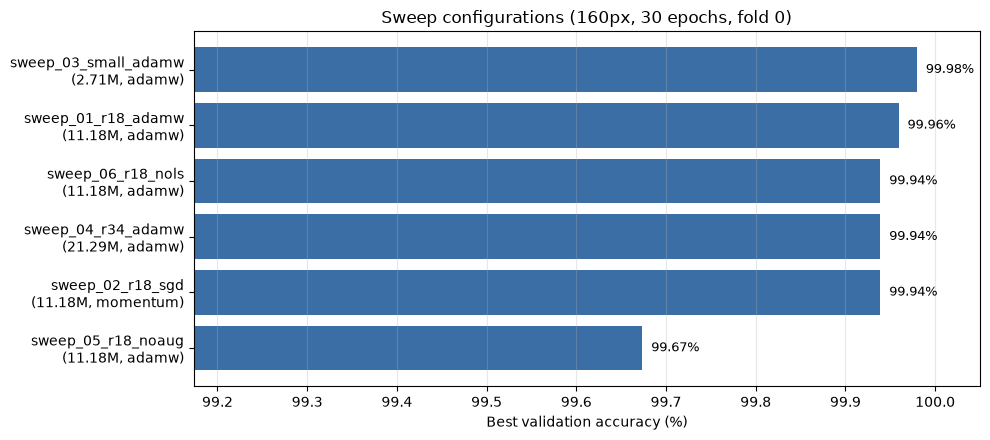

In [12]:
rows = sorted(sweep_rows, key=lambda r: r["val_acc_pct"])
names = [f'{r["run"]}\n({r["params_M"]}M, {r["opt"]})' for r in rows]
vals = [r["val_acc_pct"] for r in rows]
plt.figure(figsize=(10, 4.5))
bars = plt.barh(names, vals, color="#3b6ea5")
for b, v in zip(bars, vals):
    plt.text(v + 0.01, b.get_y() + b.get_height() / 2,
             f"{v:.2f}%", va="center", fontsize=9)
plt.xlim(min(vals) - 0.5, 100.05)
plt.xlabel("Best validation accuracy (%)")
plt.title("Sweep configurations (160px, 30 epochs, fold 0)")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


## 6. Five-fold cross-validation (224px, 90 epochs)

The selected recipe was trained on all five folds with a fixed data split and
a different model-init seed per fold. The best epoch is selected on EMA
validation accuracy.


In [13]:
cv_rows = [{'fold': 0,
  'best_epoch': 63,
  'val_acc_pct': 99.9796,
  'val_f1_pct': 99.9797,
  'used_ema': True,
  'train_images': 19598,
  'val_images': 4901},
 {'fold': 1,
  'best_epoch': 90,
  'val_acc_pct': 99.9592,
  'val_f1_pct': 99.9593,
  'used_ema': True,
  'train_images': 19598,
  'val_images': 4901},
 {'fold': 2,
  'best_epoch': 51,
  'val_acc_pct': 99.9592,
  'val_f1_pct': 99.9593,
  'used_ema': True,
  'train_images': 19598,
  'val_images': 4901},
 {'fold': 3,
  'best_epoch': 27,
  'val_acc_pct': 99.9592,
  'val_f1_pct': 99.9593,
  'used_ema': True,
  'train_images': 19598,
  'val_images': 4901},
 {'fold': 4,
  'best_epoch': 22,
  'val_acc_pct': 99.8979,
  'val_f1_pct': 99.8981,
  'used_ema': True,
  'train_images': 19604,
  'val_images': 4895}]

cv_df = pd.DataFrame(cv_rows)
mean_acc = sum(r["val_acc_pct"] for r in cv_rows) / len(cv_rows)
mean_f1 = sum(r["val_f1_pct"] for r in cv_rows) / len(cv_rows)
std_acc = (sum((r["val_acc_pct"] - mean_acc) ** 2
               for r in cv_rows) / len(cv_rows)) ** 0.5
print(f"Mean validation accuracy: {mean_acc:.4f}% +/- {std_acc:.4f}%")
print(f"Mean validation F1:       {mean_f1:.4f}%")
cv_df


Mean validation accuracy: 99.9510% +/- 0.0277%
Mean validation F1:       99.9511%


,fold,best_epoch,val_acc_pct,val_f1_pct,used_ema,train_images,val_images
0,0,63,99.9796,99.9797,True,19598,4901
1,1,90,99.9592,99.9593,True,19598,4901
2,2,51,99.9592,99.9593,True,19598,4901
3,3,27,99.9592,99.9593,True,19598,4901
4,4,22,99.8979,99.8981,True,19604,4895


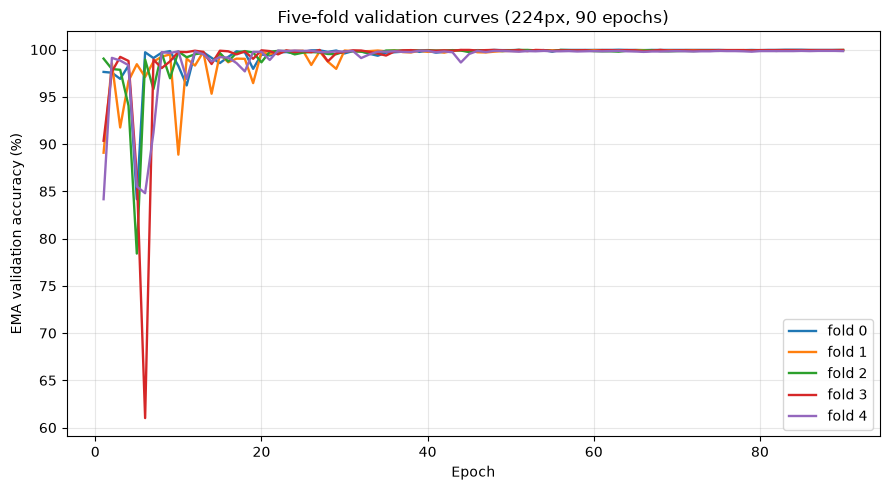

In [14]:
cv_histories = {0: {'val_acc_pct': [97.8372,
                     98.837,
                     91.4915,
                     98.3065,
                     99.4083,
                     99.6735,
                     99.2246,
                     99.4287,
                     99.1226,
                     99.4083,
                     99.6735,
                     99.5511,
                     99.796,
                     99.2246,
                     99.7756,
                     99.4899,
                     99.6531,
                     99.8776,
                     99.8572,
                     97.2251,
                     99.8776,
                     99.9184,
                     99.796,
                     99.7347,
                     99.6735,
                     99.8776,
                     99.8572,
                     99.8776,
                     99.8776,
                     99.9388,
                     99.898,
                     99.8776,
                     99.8572,
                     99.6123,
                     99.9592,
                     99.8776,
                     99.9184,
                     99.9592,
                     99.9184,
                     99.9388,
                     98.8982,
                     99.9592,
                     99.9184,
                     99.9796,
                     99.898,
                     99.9592,
                     99.8572,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9388,
                     99.9184,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.898,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9184,
                     99.9796,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592],
     'ema_val_acc_pct': [97.6331,
                         97.5515,
                         96.8986,
                         98.3065,
                         84.1665,
                         99.7143,
                         99.1022,
                         99.6735,
                         99.8368,
                         98.2657,
                         96.2049,
                         99.6939,
                         99.7143,
                         99.1226,
                         98.5717,
                         99.2246,
                         99.8164,
                         99.7143,
                         97.9596,
                         99.4695,
                         99.3675,
                         99.6939,
                         99.7347,
                         99.5919,
                         99.7347,
                         99.9184,
                         99.9184,
                         99.7552,
                         99.898,
                         99.5919,
                         99.8368,
                         99.8164,
                         99.5511,
                         99.3471,
                         99.6735,
                         99.7143,
                         99.7756,
                         99.9388,
                         99.7552,
                         99.8572,
                         99.6735,
                         99.7552,
                         99.9184,
                         99.9388,
                         99.796,
                         99.9388,
                         99.9184,
                         99.9592,
                         99.9388,
                         99.9388,
                         99.9592,
                         99.898,
                         99.9184,
                         99.9388,
                         99.7756,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9796,
                         99.9592,
                         99.9592,
                         99.9388,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9592,
                         99.9388,
                         99.9592,
                         99.9592,
                         99.9796,
                         99.9796,
                         99.9796,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592,
                         99.9592]},
 1: {'val_acc_pct': [99.6123,
                     99.3063,
                     99.0206,
                     99.7143,
                     99.7347,
                     99.2655,
                     98.5717,
                     99.3471,
                     99.3879,
                     97.5107,
                     99.8776,
                     99.7756,
                     99.6939,
                     99.7756,
                     99.8164,
                     99.7347,
                     99.3675,
                     99.3267,
                     99.4695,
                     99.8164,
                     99.2042,
                     99.8368,
                     99.8368,
                     99.9184,
                     99.4491,
                     99.7552,
                     99.898,
                     99.7756,
                     99.8776,
                     99.9184,
                     99.8164,
                     99.8572,
                     99.796,
                     99.8572,
                     99.9388,
                     99.9184,
                     99.9184,
                     99.9184,
                     99.9184,
                     99.898,
                     99.8776,
                     99.8776,
                     99.898,
                     99.8776,
                     99.796,
                     99.8164,
                     99.898,
                     99.9184,
                     99.9184,
                     99.8572,
                     99.9184,
                     99.9184,
                     99.8776,
                     99.9184,
                     99.8776,
                     99.8776,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9592,
                     99.9592,
                     99.898,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9592,
                     99.9388,
                     99.9592,
                     99.9592],
     'ema_val_acc_pct': [89.0839,
                         98.5513,
                         91.7568,
                         96.6741,
                         98.4493,
                         97.1026,
                         98.7145,
                         99.2451,
                         99.4899,
                         88.8798,
                         99.041,
                         98.3065,
                         99.7552,
                         95.3275,
                         99.5103,
                         98.6533,
                         99.041,
                         99.0206,
                         96.4497,
                         99.7143,
                         99.5103,
                         99.796,
                         99.8572,
                         99.8572,
                         99.8776,
                         98.3677,
                         99.796,
                         98.7145,
                         97.9596,
                         99.898,
                         99.8368,
                         99.8164,
                         99.8368,
                         99.898,
                         99.8164,
                         99.9184,
                         99.7347,
                         99.6939,
                         99.8776,
                         99.7552,
                         99.8164,
                         99.6735,
                         99.8572,
                         99.9388,
                         99.9184,
                         99.7143,
                         99.6939,
                         99.7756,
                         99.8368,
                         99.8572,
                         99.8368,
                         99.9388,
                         99.9184,
                         99.9184,
                         99.9184,
                         99.898,
                         99.9184,
                         99.9184,
                         99.9184,
                         99.9388,
                         99.9388,
                         99.8776,
                         99.898,
                         99.9184,
                         99.9388,
                         99.9388,
                         99.9184,
                         99.9388,
                         99.9184,
                         99.898,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9184,
                         99.9388,
                         99.9184,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9592]},
 2: {'val_acc_pct': [99.3879,
                     99.0614,
                     93.1647,
                     94.6337,
                     98.5717,
                     99.6123,
                     99.4899,
                     99.6939,
                     99.6939,
                     99.7347,
                     98.6329,
                     99.0614,
                     99.7552,
                     99.6123,
                     99.3675,
                     99.6735,
                     99.796,
                     99.9184,
                     99.2451,
                     99.0002,
                     99.8572,
                     99.796,
                     98.8982,
                     99.796,
                     99.7552,
                     99.8368,
                     99.7756,
                     99.6735,
                     99.9184,
                     99.9388,
                     99.796,
                     99.8164,
                     99.9184,
                     96.6537,
                     99.8572,
                     99.9184,
                     99.9184,
                     99.8776,
                     99.898,
                     99.8572,
                     99.7552,
                     99.9388,
                     99.8572,
                     99.8164,
                     99.9184,
                     99.8776,
                     99.8776,
                     99.9388,
                     99.8572,
                     99.9184,
                     99.9388,
                     99.9184,
                     99.898,
                     99.8572,
                     99.898,
                     99.8572,
                     99.9184,
                     99.8776,
                     99.9184,
                     99.9592,
                     99.898,
                     99.9184,
                     99.9388,
                     99.9388,
                     99.8776,
                     99.9184,
                     99.898,
                     99.8776,
                     99.898,
                     99.8572,
                     99.898,
                     99.8776,
                     99.898,
                     99.8776,
                     99.898,
                     99.9388,
                     99.9184,
                     99.9184,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9388,
                     99.9184,
                     99.898],
     'ema_val_acc_pct': [99.041,
                         97.9392,
                         97.8576,
                         94.0624,
                         78.4126,
                         98.939,
                         95.8172,
                         99.6123,
                         96.9598,
                         99.796,
                         99.1838,
                         99.5103,
                         99.6327,
                         98.6329,
                         99.6327,
                         98.735,
                         99.6531,
                         99.8368,
                         99.6939,
                         98.6533,
                         99.7756,
                         99.8572,
                         99.8368,
                         99.4899,
                         99.6735,
                         99.7347,
                         99.6939,
                         99.5307,
                         99.5103,
                         99.796,
                         99.8368,
                         99.7756,
                         99.6123,
                         99.5715,
                         99.898,
                         99.898,
                         99.898,
                         99.898,
                         99.9184,
                         99.9388,
                         99.898,
                         99.898,
                         99.9388,
                         99.898,
                         99.7347,
                         99.9184,
                         99.9184,
                         99.9184,
                         99.8368,
                         99.9184,
                         99.9592,
                         99.9592,
                         99.9184,
                         99.9388,
                         99.8368,
                         99.9592,
                         99.9388,
                         99.9184,
                         99.898,
                         99.8368,
                         99.8164,
                         99.8164,
                         99.7756,
                         99.8776,
                         99.8572,
                         99.898,
                         99.9388,
                         99.8368,
                         99.8164,
                         99.8368,
                         99.8572,
                         99.8368,
                         99.8776,
                         99.8776,
                         99.8572,
                         99.898,
                         99.898,
                         99.9184,
                         99.898,
                         99.9184,
                         99.898,
                         99.8572,
                         99.9184,
                         99.9184,
                         99.9184,
                         99.898,
                         99.898,
                         99.9184,
                         99.9388,
                         99.9388]},
 3: {'val_acc_pct': [99.143,
                     98.939,
                     99.5103,
                     97.8372,
                     99.041,
                     96.7762,
                     99.6531,
                     99.1838,
                     99.8368,
                     99.4491,
                     99.7552,
                     99.6327,
                     99.3675,
                     99.6735,
                     99.7756,
                     99.8572,
                     99.898,
                     99.8572,
                     99.898,
                     99.6939,
                     99.9184,
                     99.4695,
                     99.7347,
                     99.6735,
                     99.796,
                     99.8776,
                     99.9388,
                     99.898,
                     99.9184,
                     99.8776,
                     99.9184,
                     99.8368,
                     99.9592,
                     99.898,
                     99.8776,
                     99.898,
                     99.898,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9184,
                     99.8164,
                     99.9184,
                     99.9592,
                     99.898,
                     99.8572,
                     99.9388,
                     99.9388,
                     99.9184,
                     99.9184,
                     99.9592,
                     99.9388,
                     99.898,
                     99.9184,
                     99.9184,
                     99.898,
                     99.9184,
                     99.9388,
                     99.898,
                     99.7756,
                     99.9592,
                     99.898,
                     99.9184,
                     99.9184,
                     99.898,
                     99.8776,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9592,
                     99.9388,
                     99.9388,
                     99.9388,
                     99.9592,
                     99.9592,
                     99.9592],
     'ema_val_acc_pct': [90.3489,
                         97.6739,
                         99.2246,
                         98.7962,
                         86.6558,
                         61.008,
                         98.939,
                         98.0412,
                         98.7554,
                         99.7552,
                         99.7347,
                         99.8776,
                         99.7552,
                         98.4697,
                         99.8776,
                         99.8164,
                         99.4899,
                         99.796,
                         99.0206,
                         99.9184,
                         99.8368,
                         99.4899,
                         99.9184,
                         99.7347,
                         99.8368,
                         99.7143,
                         99.9592,
                         98.7554,
                         99.6123,
                         99.7552,
                         99.9184,
                         99.898,
                         99.7552,
                         99.5715,
                         99.3675,
                         99.796,
                         99.9184,
                         99.9388,
                         99.8776,
                         99.898,
                         99.8776,
                         99.9184,
                         99.8776,
                         99.9592,
                         99.9592,
                         99.898,
                         99.9388,
                         99.9592,
                         99.9184,
                         99.898,
                         99.9592,
                         99.8368,
                         99.9592,
                         99.9388,
                         99.8572,
                         99.9184,
                         99.9184,
                         99.9184,
                         99.9388,
                         99.8572,
                         99.9388,
                         99.9388,
                         99.9184,
                         99.9388,
                         99.9184,
                         99.796,
                         99.8776,
                         99.9592,
                         99.898,
                         99.9184,
                         99.9184,
                         99.898,
                         99.9184,
                         99.9184,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9184,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388,
                         99.9388]},
 4: {'val_acc_pct': [98.8764,
                     98.3453,
                     99.1011,
                     98.856,
                     98.5904,
                     99.6731,
                     99.4484,
                     99.4076,
                     98.713,
                     99.571,
                     99.0807,
                     99.428,
                     99.6527,
                     99.5097,
                     98.9173,
                     99.3871,
                     99.857,
                     96.2615,
                     95.0358,
                     99.714,
                     99.6118,
                     99.7753,
                     99.714,
                     99.7549,
                     99.7344,
                     99.7753,
                     99.8366,
                     99.7344,
                     99.4893,
                     99.7957,
                     99.8366,
                     99.7957,
                     99.7549,
                     99.857,
                     99.857,
                     99.8161,
                     99.8366,
                     99.7957,
                     99.9183,
                     99.7957,
                     99.857,
                     99.8366,
                     99.857,
                     99.8366,
                     99.8161,
                     99.7753,
                     99.7957,
                     99.8774,
                     99.8161,
                     99.8366,
                     99.8366,
                     99.8366,
                     99.8774,
                     99.857,
                     99.8366,
                     99.8366,
                     99.7753,
                     99.7753,
                     99.8366,
                     99.8161,
                     99.7957,
                     99.7957,
                     99.8161,
                     99.8366,
                     99.8366,
                     99.8366,
                     99.7957,
                     99.8161,
                     99.8366,
                     99.8366,
                     99.8161,
                     99.8161,
                     99.857,
                     99.857,
                     99.857,
                     99.8366,
                     99.8366,
                     99.8774,
                     99.857,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774,
                     99.8774],
     'ema_val_acc_pct': [84.1675,
                         99.1216,
                         98.8355,
                         98.3453,
                         85.5158,
                         84.8008,
                         91.1951,
                         99.7344,
                         99.6323,
                         99.8161,
                         96.8948,
                         99.7957,
                         99.5097,
                         98.7538,
                         99.2033,
                         99.142,
                         98.57,
                         97.6915,
                         99.7549,
                         99.7549,
                         98.8968,
                         99.8979,
                         99.8366,
                         99.8979,
                         99.857,
                         99.8774,
                         99.7344,
                         99.714,
                         99.7957,
                         99.7957,
                         99.857,
                         99.1011,
                         99.4893,
                         99.7753,
                         99.7753,
                         99.8161,
                         99.7549,
                         99.7344,
                         99.8774,
                         99.857,
                         99.714,
                         99.7957,
                         99.714,
                         98.6313,
                         99.5301,
                         99.857,
                         99.7344,
                         99.857,
                         99.857,
                         99.8161,
                         99.7753,
                         99.8366,
                         99.8161,
                         99.857,
                         99.8161,
                         99.8161,
                         99.8366,
                         99.7957,
                         99.8161,
                         99.8366,
                         99.8161,
                         99.8366,
                         99.857,
                         99.8161,
                         99.7957,
                         99.7549,
                         99.7957,
                         99.7957,
                         99.8161,
                         99.8366,
                         99.8161,
                         99.7957,
                         99.8161,
                         99.8161,
                         99.857,
                         99.8366,
                         99.8366,
                         99.8161,
                         99.7753,
                         99.8366,
                         99.8366,
                         99.8366,
                         99.8366,
                         99.8366,
                         99.857,
                         99.8366,
                         99.857,
                         99.857,
                         99.857,
                         99.8366]}}

plt.figure(figsize=(9, 5))
for fold, h in cv_histories.items():
    y = h["ema_val_acc_pct"] or h["val_acc_pct"]
    plt.plot(range(1, len(y) + 1), y, label=f"fold {fold}", lw=1.7)
plt.xlabel("Epoch")
plt.ylabel("EMA validation accuracy (%)")
plt.title("Five-fold validation curves (224px, 90 epochs)")
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()


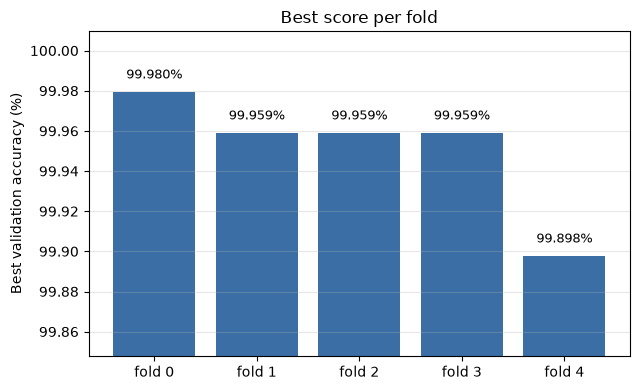

In [15]:
fig, ax = plt.subplots(figsize=(6.5, 4))
folds = [f'fold {r["fold"]}' for r in cv_rows]
accs = [r["val_acc_pct"] for r in cv_rows]
bars = ax.bar(folds, accs, color="#3b6ea5")
for b, v in zip(bars, accs):
    ax.text(b.get_x() + b.get_width() / 2, v + 0.005, f"{v:.3f}%",
            ha="center", va="bottom", fontsize=9)
ax.set_ylim(min(accs) - 0.05, max(accs) + 0.03)
ax.set_ylabel("Best validation accuracy (%)")
ax.set_title("Best score per fold")
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


## 7. Test-time augmentation and ensemble inference

Each of the five fold models predicts the test set under four deterministic
views: identity, horizontal flip, and two zoomed (and horizontally flipped)
views. Softmax probabilities are averaged within a model and then across the
five models. The final label is the argmax of the averaged probability.

The code below is the exact inference routine. It is defined here so the
notebook is self-contained; set `RUN_ENSEMBLE = True` and point to the five
checkpoints (in the repository) to regenerate `submission.csv`.


In [16]:
def make_views(size, n_views=4):
    """Deterministic TTA views: identity, hflip, and zoomed variants."""
    def view(resize_to, flip):
        ops = [T.Resize(resize_to), T.CenterCrop(size)]
        if flip:
            ops.append(T.RandomHorizontalFlip(p=1.0))
        ops += [T.ToTensor(), T.Normalize(MEAN, STD)]
        return T.Compose(ops)

    all_views = [
        view(size + 32, False),
        view(size + 32, True),
        view(int(round(size * 1.15)) + 32, False),
        view(int(round(size * 1.15)) + 32, True),
        view(size + 96, False),
        view(size + 96, True),
    ]
    return all_views[:n_views]


@torch.no_grad()
def predict_probs(model, loader, device, use_amp):
    model.eval()
    chunks = []
    for images, _ in loader:
        images = images.to(device, non_blocking=True)
        with torch.amp.autocast("cuda", enabled=use_amp):
            logits = model(images)
        chunks.append(torch.softmax(logits.float(), dim=1))
    return torch.cat(chunks)


def build_test_loader(test_csv, test_dir, transform, batch_size=128,
                      num_workers=0):
    df = pd.read_csv(test_csv)
    ds = GlassesDataset(df, test_dir, transform, is_test=True)
    loader = DataLoader(ds, batch_size=batch_size, shuffle=False,
                        num_workers=num_workers,
                        pin_memory=torch.cuda.is_available())
    return loader, df


def run_ensemble(checkpoints, test_csv, test_dir, output_csv,
                 tta_views=4, batch_size=128, num_workers=0):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    use_amp = device.type == "cuda"
    per_model = []
    for path in checkpoints:
        ckpt = torch.load(path, map_location="cpu")
        d = ckpt["config"]
        cfg_m = Config(**{k: v for k, v in d.items()
                          if k in Config.__dataclass_fields__})
        model = build_model(cfg_m)
        model.load_state_dict(ckpt["model_state_dict"])
        model.to(device).eval()
        views = make_views(cfg_m.image_size, tta_views)
        acc = None
        for transform in views:
            loader, _ = build_test_loader(
                test_csv, test_dir, transform, batch_size, num_workers)
            probs = predict_probs(model, loader, device, use_amp)
            acc = probs if acc is None else acc + probs
        per_model.append((acc / len(views)).cpu())
        torch.cuda.empty_cache()
    stacked = torch.stack(per_model)
    ensemble_probs = stacked.mean(dim=0)
    preds = ensemble_probs.argmax(dim=1).tolist()
    df = pd.read_csv(test_csv)
    pd.DataFrame({"id": df["id"].astype(str),
                  "glasses": preds}).to_csv(output_csv, index=False)
    print(f"Saved {output_csv}: {len(preds)} rows, "
          f"{sum(preds)} glasses, {len(preds) - sum(preds)} no-glasses")
    return ensemble_probs, preds


In [17]:
ensemble_summary = {'checkpoints': ['fold0_best.pt', 'fold1_best.pt', 'fold2_best.pt', 'fold3_best.pt', 'fold4_best.pt'],
 'tta_views': 4,
 'image_size': 224,
 'n_test': 5412,
 'glasses': 2984,
 'no_glasses': 2428,
 'mean_confidence': 0.9526850581169128,
 'unanimous': 5378,
 'model_disagreements': 34,
 'val_accs': [0.9997959600081616,
              0.9995919200163232,
              0.9995919200163232,
              0.9995919200163232,
              0.9989785495403473],
 'kaggle_score': 0.99872,
 'note': '5 fold models x 4 deterministic TTA views; probability probability averaging'}

summary_df = pd.DataFrame([{
    "test images": ensemble_summary["n_test"],
    "glasses": ensemble_summary["glasses"],
    "no glasses": ensemble_summary["no_glasses"],
    "unanimous": ensemble_summary["unanimous"],
    "model disagreements": ensemble_summary["model_disagreements"],
    "mean confidence": round(ensemble_summary["mean_confidence"], 4),
    "Test score": ensemble_summary["kaggle_score"],
}])
summary_df


,test images,glasses,no glasses,unanimous,model disagreements,mean confidence,Test score
0,5412,2984,2428,5378,34,0.9527,0.99872


In [18]:
RUN_ENSEMBLE = False
if RUN_ENSEMBLE:
    checkpoints = [f"../experiments/cv_final/fold{i}_best.pt"
                   for i in range(5)]
    run_ensemble(checkpoints, TEST_CSV, TEST_DIR,
                 "submission_selfcontained.csv", tta_views=4,
                 batch_size=128, num_workers=0)
else:
    print("Set RUN_ENSEMBLE = True and provide the five fold checkpoints "
          "from the repository to regenerate the submission.")


Set RUN_ENSEMBLE = True and provide the five fold checkpoints from the repository to regenerate the submission.


In [19]:
submission_preview = [{'id': '1', 'glasses': 0},
 {'id': '2', 'glasses': 0},
 {'id': '3', 'glasses': 1},
 {'id': '4', 'glasses': 0},
 {'id': '5', 'glasses': 1},
 {'id': '6', 'glasses': 0},
 {'id': '7', 'glasses': 1},
 {'id': '8', 'glasses': 0},
 {'id': '9', 'glasses': 0},
 {'id': '10', 'glasses': 0}]
submission_counts = {'rows': 5412, 'glasses': 2984, 'no_glasses': 2428}

print(f"Submission: {submission_counts['rows']} rows | "
      f"{submission_counts['glasses']} glasses | "
      f"{submission_counts['no_glasses']} no-glasses")
pd.DataFrame(submission_preview)


Submission: 5412 rows | 2984 glasses | 2428 no-glasses


,id,glasses
0,1,0
1,2,0
2,3,1
3,4,0
4,5,1
5,6,0
6,7,1
7,8,0
8,9,0
9,10,0


## 8. Results and discussion

The convolutional inductive bias, not external knowledge, accounts for the
large improvement over the fully-connected baseline: local receptive fields
and translation equivariance match the structure of the task. Strong
augmentation, label smoothing, warmup + cosine scheduling, AMP and EMA
stabilize training. Five-fold ensembling with TTA reduces prediction variance:
only 34 of 5,412 test images have any model disagreement, and 5,378 are
unanimous across all five models.


In [20]:
comparison = [
    {"model": "MLP (earlier baseline)", "input": "64x64",
     "params_M": 6.46, "val_acc_pct": 86.69},
    {"model": "ResNet-style CNN, 5-fold mean", "input": "224x224",
     "params_M": 11.18, "val_acc_pct": 99.9510},
]
pd.DataFrame(comparison)


,model,input,params_M,val_acc_pct
0,MLP (earlier baseline),64x64,6.46,86.690
1,"ResNet-style CNN, 5-fold mean",224x224,11.18,99.951


**Final submission.** `submission.csv` has 5,412 rows and the columns
`id,glasses`. The labels are the argmax of the averaged neural-network
softmax probabilities. Test score: **0.99872** (approximately 7 errors
out of 5,412). The final labels are the argmax of the averaged network probabilities.


## 9. Reproducibility

- **Tunable hyperparameters.** `Config` and the live demo cell expose
  architecture, optimizer, loss, schedule, batch size, augmentation and
  annealing settings.
- **Repository:** https://github.com/D3LET3-57/GlassesNet
- **Report:** `report.pdf`.

**Reproducing the final models.** The final runs used 224px, 90 epochs, batch
128, AdamW at 1e-3, EMA 0.999 and the same five-fold split. On one
RTX 6000 Ada this took about 2 hours for all five folds. The exact command in
the repository is:

```bash
python -m src.run --config experiments/configs/final.json --fold 0 --run-name cv_final
```

The notebook's `fit` function is the same implementation, so you can also run
`fit(Config(num_epochs=90, image_size=224, batch_size=128, num_workers=12,
device='cuda'), TRAIN_CSV, TRAIN_DIR)` for each fold.

**Additional ablation.** A 288px fine-tune of the five fold models matched the
224px cross-validation mean exactly (99.9510%); it changed only 4 of 5,412
test predictions, fixing two and breaking two, so it was not used. The
submitted ensemble is the 224px five-fold model.
